Label-noise robustness BiLSTM

In [1]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import callbacks, layers, models
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42
NOISE_RATE = 0.10
tf.keras.utils.set_random_seed(SEED)

In [2]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

train_df = pd.read_csv(SPLITS_DIR / "noise10" / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")  # original, unmodified — never touch val/test labels

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)

y_train = label_encoder.transform(train_df["category"])  # noisy labels, by design
y_val = label_encoder.transform(val_df["category"])

print("Train (noisy) rows:", len(train_df), "| flipped:", int(train_df["is_flipped"].sum()))
print("Val (clean) rows:", len(val_df))
print("Classes:", LABEL_ORDER)

Train (noisy) rows: 50000 | flipped: 5000
Val (clean) rows: 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [3]:
VOCAB_SIZE = 20000

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["text"])  # fit on this fold's TRAIN ONLY

train_token_counts = train_df["text"].fillna("").astype(str).str.split().str.len()
p95 = int(np.percentile(train_token_counts, 95))
MAX_LEN = int(np.clip(p95, 20, 200))
print(f"95th percentile train token count: {p95}, MAX_LEN clamped to: {MAX_LEN}")


def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")


X_train = to_padded(train_df["text"])
X_val = to_padded(val_df["text"])

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

95th percentile train token count: 554, MAX_LEN clamped to: 200


X_train shape: (50000, 200)
X_val shape: (48178, 200)


In [4]:
EMBEDDING_DIM = 128
LSTM_UNITS = 128
DROPOUT = 0.3
RECURRENT_DROPOUT = 0.0  # keep cuDNN kernel path — see CLAUDE.md note on LSTM_a

model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
    layers.Bidirectional(
        layers.LSTM(LSTM_UNITS, dropout=DROPOUT, recurrent_dropout=RECURRENT_DROPOUT, return_sequences=False)
    ),
    layers.Dropout(DROPOUT),
    layers.Dense(64, activation="relu"),
    layers.Dropout(DROPOUT),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,840,136 (10.83 MB)

 Trainable params: 2,840,136 (10.83 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
LEARNING_RATE = 1e-3

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [6]:
MODELS_DIR = Path("../../weights/noise10/lstm")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
EPOCHS = 15

callback_list = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "lstm_model.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

In [7]:
start_time = time.time()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callback_list,
    verbose=2,
)
train_time_sec = time.time() - start_time
print(f"Training took {train_time_sec:.1f}s over {len(history.history['loss'])} epochs")

Epoch 1/15


782/782 - 341s - 437ms/step - accuracy: 0.5919 - loss: 1.2985 - val_accuracy: 0.7749 - val_loss: 0.7268


Epoch 2/15


782/782 - 352s - 450ms/step - accuracy: 0.7455 - loss: 0.9255 - val_accuracy: 0.7758 - val_loss: 0.7159


Epoch 3/15


782/782 - 369s - 472ms/step - accuracy: 0.7947 - loss: 0.7662 - val_accuracy: 0.7551 - val_loss: 0.7675


Epoch 4/15


782/782 - 373s - 477ms/step - accuracy: 0.8313 - loss: 0.6208 - val_accuracy: 0.7519 - val_loss: 0.8374


Epoch 5/15


782/782 - 377s - 483ms/step - accuracy: 0.8614 - loss: 0.5006 - val_accuracy: 0.7272 - val_loss: 1.0412


Training took 1812.6s over 5 epochs


In [8]:
model = tf.keras.models.load_model(MODELS_DIR / "lstm_model.keras")

In [9]:
inf_start = time.time()
y_pred_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
inf_time_sec = time.time() - inf_start
y_pred = np.argmax(y_pred_probs, axis=1)

report_dict = classification_report(
    y_val, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0
)
print(classification_report(y_val, y_pred, target_names=LABEL_ORDER, zero_division=0))

cm = confusion_matrix(y_val, y_pred)
val_accuracy = report_dict["accuracy"]
print(f"Val accuracy: {val_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(val_df) * 1000:.3f} ms/sample")
print("\nLSTM_a in-distribution test accuracy for comparison: 0.8333 (see results/lstm/LSTM_a_metrics.json)")

               precision    recall  f1-score   support

     Business       0.78      0.75      0.76      6323
Entertainment       0.78      0.86      0.82     12064
       Health       0.62      0.74      0.67      4196
     Politics       0.84      0.66      0.74      6238
      Science       0.48      0.53      0.50      1609
       Sports       0.83      0.92      0.87      5854
   Technology       0.80      0.74      0.77      5828
        World       0.85      0.75      0.80      6066

     accuracy                           0.78     48178
    macro avg       0.75      0.74      0.74     48178
 weighted avg       0.78      0.78      0.78     48178

Val accuracy: 0.7758
Inference time: 38.23s total, 0.794 ms/sample

LSTM_a in-distribution test accuracy for comparison: 0.8333 (see results/lstm/LSTM_a_metrics.json)


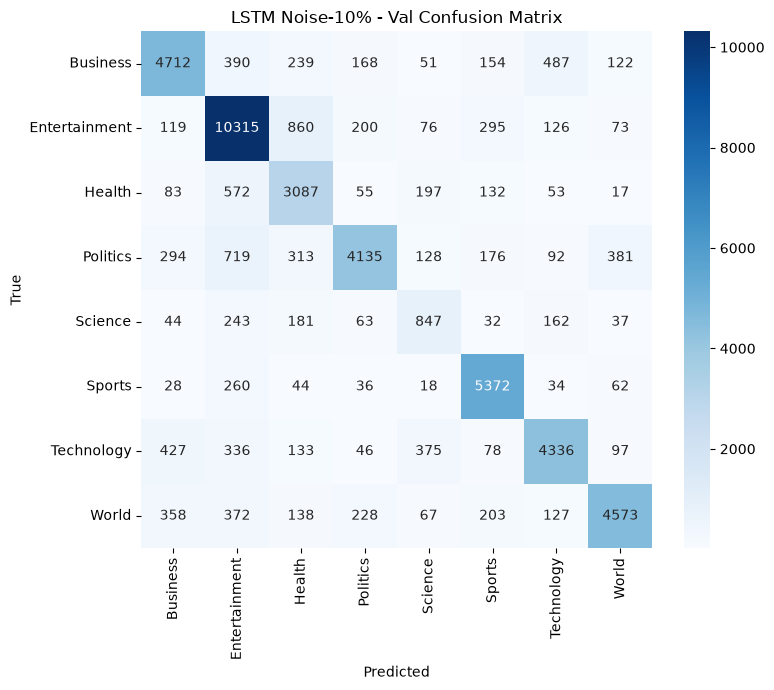

In [10]:
RESULTS_DIR = Path("../../../results/lstm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("LSTM Noise-10% - Val Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "lstm_noise10_confusion_matrix.png", dpi=150)
plt.show()
plt.close()

In [11]:
with open(MODELS_DIR / "tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

config = {
    "max_len": MAX_LEN,
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "lstm_units": LSTM_UNITS,
    "batch_size": BATCH_SIZE,
    "epochs_planned": EPOCHS,
    "learning_rate": LEARNING_RATE,
}
with open(MODELS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

metrics = {
    "model_family": "lstm",
    "model_name": "bilstm-scratch-embed-noise10",
    "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
    "label_order": LABEL_ORDER,
    "noise_rate": NOISE_RATE,
    "config": {
        **config,
        "epochs_trained": len(history.history["loss"]),
    },
    "train": {
        "n_train": len(train_df),
        "n_flipped": int(train_df["is_flipped"].sum()),
        "train_time_sec": train_time_sec,
        "epochs_trained": len(history.history["loss"]),
        "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
    },
    "test": {
        "n_test": len(val_df),
        "eval_split": "val (original, unmodified)",
        "accuracy": float(val_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(val_df) * 1000,
    },
    "environment": {
        "framework": "tensorflow",
        "framework_version": tf.__version__,
        "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "lstm_noise10_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:")
print(" ", MODELS_DIR / "lstm_model.keras")
print(" ", MODELS_DIR / "tokenizer.pkl")
print(" ", MODELS_DIR / "config.json")
print(" ", RESULTS_DIR / "lstm_noise10_metrics.json")
print(" ", RESULTS_DIR / "lstm_noise10_confusion_matrix.png")

Saved:
  ..\..\weights\noise10\lstm\lstm_model.keras
  ..\..\weights\noise10\lstm\tokenizer.pkl
  ..\..\weights\noise10\lstm\config.json
  ..\..\..\results\lstm\lstm_noise10_metrics.json
  ..\..\..\results\lstm\lstm_noise10_confusion_matrix.png
